In [22]:
%reload_ext autoreload
%autoreload 2
from globalSettings import *
from Utils import *
from Dataset import *
from Models import *

# init variables
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
pl.seed_everything(1204)


Global seed set to 1204


cuda


1204

In [2]:
df_train, df_val, test_data = load_data()

Using downloaded and verified file: ./dataset//VOC_train/VOCtrainval_06-Nov-2007.tar
Extracting ./dataset//VOC_train/VOCtrainval_06-Nov-2007.tar to ./dataset//VOC_train
Using downloaded and verified file: ./dataset//VOC_trainval/VOCtrainval_06-Nov-2007.tar
Extracting ./dataset//VOC_trainval/VOCtrainval_06-Nov-2007.tar to ./dataset//VOC_trainval
Using downloaded and verified file: ./dataset//VOC_test/VOCtest_06-Nov-2007.tar
Extracting ./dataset//VOC_test/VOCtest_06-Nov-2007.tar to ./dataset//VOC_test
Total training set elements: 2501
Total training set elements: 5011


In [13]:
traindataset, trainloader = get_train_load_obj(df_train)
valdataset, valloader = get_val_load_obj(df_val)

In [34]:
%reload_ext autoreload
%autoreload 3

MODEL_SAVE_PATH = f'./models/base_model_AlexNet_{BaseModelConfig.batch_size}_{BaseModelConfig.num_epochs}_{BaseModelConfig.lr}_{BaseModelConfig.patch_dim}_{BaseModelConfig.gap}.pt'
model = AlexNetModel()
trainer = pl.Trainer(gpus=1, max_epochs=300, auto_scale_batch_size= True, enable_progress_bar= True, default_root_dir=MODEL_SAVE_PATH)
trainer.fit(model, trainloader, valloader)
#############################################
# Initialized Optimizer, criterion, scheduler
#############################################

# optimizer = optim.Adam(model.parameters(), lr=BaseModelConfig.lr)
# criterion = torch.nn.CrossEntropyLoss()
# scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 
#                                            mode='min',
#                                            patience=5,
#                                            factor=0.3, verbose=True)

ValueError: `self.log(loss, loss)` was called, but `str` values cannot be logged

In [ ]:
############################
# Training/Validation Engine
############################
MODEL_SAVE_PATH = f'./models/base_model_Efron_{BaseModelConfig.batch_size}_{BaseModelConfig.num_epochs}_{BaseModelConfig.lr}_{BaseModelConfig.patch_dim}_{BaseModelConfig.gap}.pt'


global_trn_loss = []
global_val_loss = []

for epoch in range(BaseModelConfig.num_epochs):
    train_running_loss = []
    val_running_loss = []
    start_time = time.time()
    model.train()
    
    for idx, data in tqdm(enumerate(trainloader), total=int(len(traindataset)/BaseModelConfig.batch_size)):
        uniform_patch, random_patch, random_patch_label = data[0].to(device), data[1].to(device), data[2].to(device)
        optimizer.zero_grad()
        output, output_fc6_uniform, output_fc6_random = model(uniform_patch, random_patch)
        loss = criterion(output, random_patch_label)
        loss.backward()
        optimizer.step()
        
        train_running_loss.append(loss.item())
    correct = 0
    total = 0
    model.eval()
    with torch.no_grad():
        for idx, data in tqdm(enumerate(valloader), total=int(len(valdataset)/BaseModelConfig.batch_size)):
            uniform_patch, random_patch, random_patch_label = data[0].to(device), data[1].to(device), data[2].to(device)
            output, output_fc6_uniform, output_fc6_random = model(uniform_patch, random_patch)
            loss = criterion(output, random_patch_label)
            val_running_loss.append(loss.item())

            _, predicted = torch.max(output.data, 1)
            total += random_patch_label.size(0)
            correct += (predicted == random_patch_label).sum()
    print('Val Progress --- total:{}, correct:{}'.format(total, correct.item()))
    print('Val Accuracy of the network on the 10000 test images: {}%'.format(100 * correct / total))
        
    global_trn_loss.append(sum(train_running_loss) / len(train_running_loss))
    global_val_loss.append(sum(val_running_loss) / len(val_running_loss))
    
    scheduler.step(global_val_loss[-1])
    
    print('Epoch [{}/{}], TRNLoss:{:.4f}, VALLoss:{:.4f}, Time:{:.2f}'.format(
        epoch + 1, BaseModelConfig.num_epochs, global_trn_loss[-1], global_val_loss[-1],
        (time.time() - start_time) / 60))
    
    if epoch % 20 == 0:
        torch.save(
            {
                'epoch': BaseModelConfig.num_epochs,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                'global_trnloss': global_trn_loss,
                'global_valloss': global_val_loss
            }, MODEL_SAVE_PATH)


In [13]:
now = datetime.now()
current_time = now.strftime("%d/%m_%H:%M")
print(current_time)

25/02_10:21


In [7]:
now = datetime.now()
current_time = now.strftime("%d/%m_%H:%M")
MODEL_TO_LOAD = f'./models/base_model_Efron_64_{BaseModelConfig.num_epochs}_{BaseModelConfig.lr}_{BaseModelConfig.patch_dim}_{BaseModelConfig.gap}.pt'

#model = OurNetwork().to(device)

checkpoint_Efron = torch.load(MODEL_TO_LOAD, map_location='cuda')
#model.load_state_dict(checkpoint['model_state_dict'])
min(checkpoint_Efron['global_trnloss'])


RuntimeError: CUDA out of memory. Tried to allocate 128.00 MiB (GPU 0; 2.95 GiB total capacity; 1.71 GiB already allocated; 78.12 MiB free; 1.73 GiB reserved in total by PyTorch) If reserved memory is >> allocated memory try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

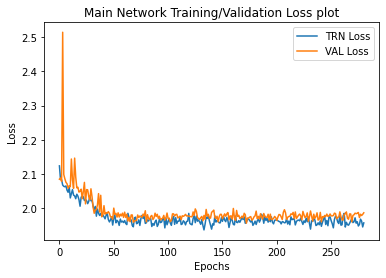

In [6]:
plt.plot(range(len(checkpoint_Efron['global_trnloss'])), checkpoint_Efron['global_trnloss'], label='TRN Loss')
plt.plot(range(len(checkpoint_Efron['global_valloss'])), checkpoint_Efron['global_valloss'], label='VAL Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Main Network Training/Validation Loss plot')
plt.legend()
plt.show()

In [ ]:

resModel = ResNetwork().to(device)

print(resModel)

#############################################
# Initialized Optimizer, criterion, scheduler
#############################################

optimizer = optim.Adam(resModel.parameters(), lr=BaseModelConfig.lr)
criterion = torch.nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 
                                           mode='min',
                                           patience=5,
                                           factor=0.3, verbose=True)

In [ ]:
torch.cuda.empty_cache()

In [ ]:
del random_patch
del uniform_patch
del random_patch_label

In [ ]:

MODEL_SAVE_PATH = f'./models/base_model_ResNet34_{BaseModelConfig.batch_size}_{BaseModelConfig.num_epochs}_{BaseModelConfig.lr}_{BaseModelConfig.patch_dim}_{BaseModelConfig.gap}.pt'

global_trn_loss = []
global_val_loss = []

for epoch in range(BaseModelConfig.num_epochs):
    train_running_loss = []
    val_running_loss = []
    start_time = time.time()
    resModel.train()
    
    for idx, data in tqdm(enumerate(trainloader), total=int(len(traindataset)/BaseModelConfig.batch_size)):
        uniform_patch, random_patch, random_patch_label = data[0].to(device), data[1].to(device), data[2].to(device)
        optimizer.zero_grad()
        output, output_fc6_uniform, output_fc6_random = resModel(uniform_patch, random_patch)
        loss = criterion(output, random_patch_label)
        loss.backward()
        optimizer.step()
        
        train_running_loss.append(loss.item())
    correct = 0
    total = 0
    resModel.eval()
    with torch.no_grad():
        for idx, data in tqdm(enumerate(valloader), total=int(len(valdataset)/BaseModelConfig.batch_size)):
            uniform_patch, random_patch, random_patch_label = data[0].to(device), data[1].to(device), data[2].to(device)
            output, output_fc6_uniform, output_fc6_random = resModel(uniform_patch, random_patch)
            loss = criterion(output, random_patch_label)
            val_running_loss.append(loss.item())
            _, predicted = torch.max(output.data, 1)
            total += random_patch_label.size(0)
            correct += (predicted == random_patch_label).sum()
    print('Val Progress --- total:{}, correct:{}'.format(total, correct.item()))
    print('Val Accuracy of the network on the 10000 test images: {}%'.format(100 * correct / total))
        
    global_trn_loss.append(sum(train_running_loss) / len(train_running_loss))
    global_val_loss.append(sum(val_running_loss) / len(val_running_loss))
    
    scheduler.step(global_val_loss[-1])
    
    print('Epoch [{}/{}], TRNLoss:{:.4f}, VALLoss:{:.4f}, Time:{:.2f}'.format(
        epoch + 1, BaseModelConfig.num_epochs, global_trn_loss[-1], global_val_loss[-1],
        (time.time() - start_time) / 60))
    
    if epoch % 20 == 0:
        torch.save(
            {
                'epoch': BaseModelConfig.num_epochs,
                'model_state_dict': resModel.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                'global_trnloss': global_trn_loss,
                'global_valloss': global_val_loss
            }, MODEL_SAVE_PATH)


In [5]:
now = datetime.now()
current_time = now.strftime("%d/%m_%H:%M")
MODEL_TO_LOAD = f'./models/base_model_ResNet18_{BaseModelConfig.batch_size}_{BaseModelConfig.num_epochs}_{BaseModelConfig.lr}_{BaseModelConfig.patch_dim}_{BaseModelConfig.gap}_{current_time}.pt'

model = ResNetwork().to(device)

checkpoint = torch.load(MODEL_TO_LOAD, map_location='cuda')
#model.load_state_dict(checkpoint['model_state_dict'])


In [7]:
min(checkpoint['global_trnloss'])

1.8932371200269955

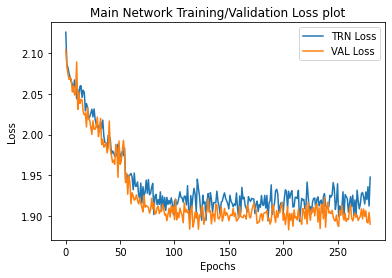

In [6]:
plt.plot(range(len(checkpoint['global_trnloss'])), checkpoint['global_trnloss'], label='TRN Loss')
plt.plot(range(len(checkpoint['global_valloss'])), checkpoint['global_valloss'], label='VAL Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Main Network Training/Validation Loss plot')
plt.legend()
plt.show()